# Фінальний проєкт. Прогнозування відтоку клієнтів (customer churn)

Задача: за анонімізованими маркетинговими даними телекомунікаційної компанії передбачити, які клієнти можуть змінити постачальника послуг.

Бінарна класифікація на наборі з 230 ознак (190 числових і 40 категоріальних) із суттєвим дисбалансом класів. Метрика оцінювання - збалансована точність (balanced accuracy).

## 1. Імпорт пакетів і завантаження даних

Пакет `catboost` не входить до стандартного набору бібліотек, тому за потреби встановлюємо його.

In [1]:
try:
    import catboost
except ImportError:
    %pip install -q catboost

In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (balanced_accuracy_score,
                             roc_auc_score,
                             classification_report,
                             ConfusionMatrixDisplay)
from catboost import CatBoostClassifier, Pool

In [3]:
COMPETITION = 'ml-fundamentals-and-applications-2025-07-08'

DATA_DIRS = [
    Path('/kaggle/input/competitions') / COMPETITION,
    Path('/kaggle/input') / COMPETITION,
    Path('../datasets')]

DATA_URL = ('https://raw.githubusercontent.com/goitacademy/'
            'MACHINE-LEARNING-NEO/main/competition/')


def data_path(filename):
    for folder in DATA_DIRS:
        if (folder / filename).exists():
            return folder / filename
    return DATA_URL + filename


data_path('final_proj_data.csv')

PosixPath('../datasets/final_proj_data.csv')

In [4]:
data = pd.read_csv(data_path('final_proj_data.csv'))
test = pd.read_csv(data_path('final_proj_test.csv'))

print(f'train: {data.shape} | test: {test.shape}')

train: (10000, 231) | test: (2500, 230)


## 2. Дослідницький аналіз даних

### Перший погляд на дані

In [5]:
data.head()

,Var1,Var2,Var3,Var4,Var5,Var6,Var7,Var8,Var9,Var10,...,Var222,Var223,Var224,Var225,Var226,Var227,Var228,Var229,Var230,y
0,NaN,NaN,NaN,NaN,NaN,812.0,14.0,NaN,NaN,NaN,...,catzS2D,jySVZNlOJy,NaN,xG3x,Aoh3,ZI9m,ib5G6X1eUxUn6,mj86,NaN,0
1,NaN,NaN,NaN,NaN,NaN,2688.0,7.0,NaN,NaN,NaN,...,i06ocsg,LM8l689qOp,NaN,kG3k,WqMG,RAYp,55YFVY9,mj86,NaN,0
2,NaN,NaN,NaN,NaN,NaN,1015.0,14.0,NaN,NaN,NaN,...,P6pu4Vl,LM8l689qOp,NaN,kG3k,Aoh3,ZI9m,R4y5gQQWY8OodqDV,am7c,NaN,0
3,NaN,NaN,NaN,NaN,NaN,168.0,0.0,NaN,NaN,NaN,...,BNrD3Yd,LM8l689qOp,NaN,NaN,FSa2,RAYp,F2FyR07IdsN7I,NaN,NaN,0
4,NaN,NaN,NaN,NaN,NaN,14.0,0.0,NaN,NaN,NaN,...,3B1QowC,LM8l689qOp,NaN,NaN,WqMG,RAYp,F2FyR07IdsN7I,NaN,NaN,0


Ознаки повністю анонімізовані: назви виду `Var1`...`Var230`, а значення категоріальних - беззмістовні рядки на кшталт `KXMrEyXXnK`. Це означає, що предметних знань про телеком тут застосувати неможливо: жодну ознаку не вийде осмислено перетворити чи скомбінувати вручну. Тому весь відбір ознак нижче спирається лише на статистику самих даних.

Перед аналізом перевіряємо базову цілісність набору.

In [6]:
print(f'повних дублікатів рядків: {data.duplicated().sum()}')

both = pd.concat([data[test.columns], test])
print(f'рядків, спільних із валідаційним набором: {both.duplicated().sum()}')

print(f'колонок з єдиним значенням: {(data.nunique(dropna=True) == 1).sum()}')

повних дублікатів рядків: 0
рядків, спільних із валідаційним набором: 0
колонок з єдиним значенням: 7


### Розподіл цільової змінної

In [7]:
target = data.pop('y')

target.value_counts(normalize=True)

y
0    0.8695
1    0.1305
Name: proportion, dtype: float64

Класи сильно незбалансовані: клієнтів, схильних до відтоку, лише ~13%. Тому звичайна accuracy була б неінформативною (модель, яка завжди прогнозує клас 0, отримала б 87%), і саме тому змагання оцінюється за balanced accuracy.

### Типи ознак і пропущені значення

In [8]:
data.dtypes.value_counts()

float64    191
object      38
int64        1
Name: count, dtype: int64

In [9]:
na_share = data.isna().mean()

print(f'колонок без жодного значення: {na_share.eq(1).sum()}')
print(f'колонок із часткою пропусків > 0.8: {na_share.gt(0.8).sum()}')
print(f'колонок із часткою пропусків < 0.8: {na_share.lt(0.8).sum()}')

колонок без жодного значення: 18
колонок із часткою пропусків > 0.8: 154
колонок із часткою пропусків < 0.8: 76


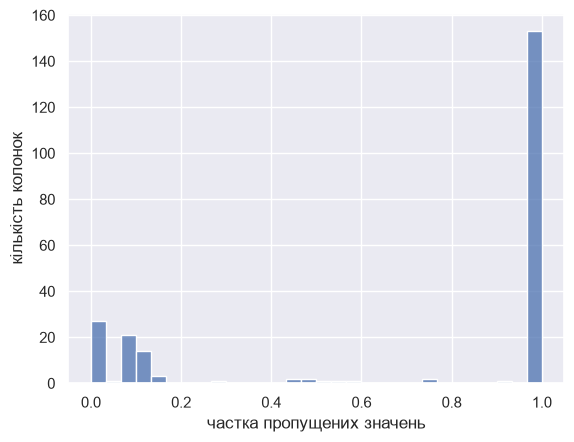

In [10]:
sns.set_theme()

ax = sns.histplot(na_share, bins=30)
ax.set(xlabel='частка пропущених значень', ylabel='кількість колонок')

plt.show()

Розподіл пропусків різко двомодальний: колонки або майже повністю заповнені, або майже повністю порожні. Проміжних випадків майже немає, тому поріг для відкидання можна обрати доволі вільно - відкидаємо колонки, заповнені менш ніж на 20%, оскільки відновити їх неможливо.

Кількість пропусків - це ще не все: важливо, чи сама пропущеність повʼязана з цільовою змінною. Порівнюємо частку пропусків у кожній колонці окремо для клієнтів, які пішли, і тих, хто залишився.

In [11]:
dense_cols = data.columns[na_share.lt(0.8)]

by_class = data[dense_cols].isna().groupby(target).mean().T
by_class.columns = ['клас 0', 'клас 1']
by_class['різниця'] = (by_class['клас 1'] - by_class['клас 0']).abs()

by_class.sort_values('різниця', ascending=False).head(5).round(3)

,клас 0,клас 1,різниця
Var214,0.456,0.757,0.301
Var200,0.456,0.757,0.301
Var225,0.473,0.765,0.292
Var229,0.519,0.805,0.287
Var126,0.253,0.444,0.191


In [12]:
row_na = data.isna().sum(axis=1)

print(f'пропусків у рядку: від {row_na.min()} до {row_na.max()}, '
      f'медіана {row_na.median():.0f}')
print(f'у середньому для клієнтів, які залишились: {row_na[target == 0].mean():.1f}')
print(f'у середньому для клієнтів, які пішли:      {row_na[target == 1].mean():.1f}')

пропусків у рядку: від 153 до 181, медіана 160
у середньому для клієнтів, які залишились: 160.1
у середньому для клієнтів, які пішли:      162.1


Пропущеність окремих колонок помітно повʼязана з відтоком: у `Var225` і `Var229` різниця між класами сягає 29 відсоткових пунктів. Отже, сам факт відсутності значення несе інформацію, і заповнювати пропуски середнім чи медіаною для основної моделі недоцільно - це стерло б цей сигнал. CatBoost працює з пропусками нативно, розглядаючи їх як окрему гілку розбиття, тому залишаємо їх без змін.

Натомість загальна кількість пропусків у рядку майже не відрізняється між класами (160.1 проти 162.1), тому від похідної ознаки `n_missing` не варто очікувати багато - на відміну від пропущеності конкретних колонок.

### Масштаб числових ознак

In [13]:
numeric_stats = (data[dense_cols]
                 .select_dtypes(include='number')
                 .describe().T[['min', '50%', 'max', 'std']]
                 .sort_values('max', ascending=False))

print(f'числових ознак: {len(numeric_stats)}')

pd.concat([numeric_stats.head(3), numeric_stats.tail(3)]).round(3)

числових ознак: 42


,min,50%,max,std
Var76,0.000,856516.00,19353600.0,1856475.422
Var38,0.000,1295544.00,18144000.0,3027801.210
Var149,0.000,46221.00,16934400.0,701319.838
Var143,0.000,0.00,18.0,0.633
Var57,0.001,3.57,7.0,2.038
Var173,0.000,0.00,2.0,0.098


Масштаби ознак відрізняються на сім порядків: у найбільшої максимум сягає мільйонів, у найменшої не перевищує кількох одиниць. Для моделей, чутливих до масштабу - логістичної регресії та методу головних компонент, - нормалізація обовʼязкова, тому в розділі 4 вона стоїть окремим кроком ML-конвеєра. Дерева рішень і градієнтний бустинг до масштабу нечутливі: вони працюють із порядком значень, а не з їхньою величиною, тому для CatBoost нормалізація не потрібна.

### Категоріальні ознаки

In [14]:
cols_keep = data.columns[na_share.lt(0.8)]

cat_cardinality = (data[cols_keep]
                   .select_dtypes(include='object')
                   .nunique()
                   .sort_values(ascending=False))

print(f'категоріальних ознак: {len(cat_cardinality)}')
print(f'сумарно унікальних категорій: {cat_cardinality.sum()}')
print(f'на один рядок даних: {cat_cardinality.sum() / len(data):.1f}')

buckets = pd.cut(cat_cardinality, [0, 10, 100, 1000, 10 ** 6],
                 labels=['до 10', '11-100', '101-1000', 'понад 1000'])

print()
print(buckets.value_counts().sort_index().to_string())

cat_cardinality.head(10)

категоріальних ознак: 34
сумарно унікальних категорій: 28273
на один рядок даних: 2.8

до 10         14
11-100         9
101-1000       3
понад 1000     8


Var217    5529
Var200    4478
Var214    4478
Var202    3802
Var222    2100
Var220    2100
Var198    2100
Var199    1850
Var216     977
Var192     297
dtype: int64

In [15]:
for col in cat_cardinality.head(3).index:
    counts = data[col].value_counts()
    print(f'{col}: {cat_cardinality[col]:>5} категорій | '
          f'{(counts == 1).mean():.0%} трапляються рівно один раз')

Var217:  5529 категорій | 71% трапляються рівно один раз
Var200:  4478 категорій | 90% трапляються рівно один раз
Var214:  4478 категорій | 90% трапляються рівно один раз


Кардинальність украй нерівномірна: 14 ознак мають до 10 категорій, а вісім - понад тисячу, причому `Var217` містить 5529 категорій на 10 000 спостережень. Сумарно по всіх категоріальних ознаках налічується 28273 унікальні категорії - саме стільки колонок дало б one-hot кодування, тобто майже втричі більше, ніж рядків у наборі. Такий варіант відпадає.

Кодування за цільовою змінною теж проблемне: 71% категорій `Var217` трапляються рівно один раз, а в `Var200` і `Var214` - 90%. Для такої категорії середнє значення цільової змінної дорівнює мітці єдиного спостереження, тобто кодування просто переносить відповідь в ознаку.

Саме тому основною моделлю обрано `CatBoostClassifier`: він обробляє категорії нативно через впорядковані цільові статистики (ordered target statistics), де значення для кожного спостереження рахується лише за попередніми рядками випадкової перестановки, і мітка поточного рядка в нього не потрапляє. CatBoost - алгоритм градієнтного бустингу, тобто ансамблевий метод із теми 9. Це не AutoML-бібліотека: ознаки, модель і параметри задано явно. Порівняння з кодуванням за цільовою змінною наведено в розділі 5.

### Дублювання та узагальнення категорій

Дві ознаки - `Var200` і `Var214` - мають однакову кількість категорій, тому перевіряємо, чи не є вони просто різними позначеннями одного й того ж.

In [16]:
pair = data[['Var200', 'Var214']].dropna()

print(f'рядків без пропусків: {len(pair)}')
print(f'унікальних значень Var200: {pair["Var200"].nunique()}')
print(f'унікальних значень Var214: {pair["Var214"].nunique()}')
print(f'унікальних пар (Var200, Var214): {len(pair.drop_duplicates())}')

рядків без пропусків: 5043
унікальних значень Var200: 4478
унікальних значень Var214: 4478
унікальних пар (Var200, Var214): 4478


Кількість унікальних пар збігається з кількістю категорій кожної ознаки, тобто між ними існує взаємно однозначна відповідність: одна ознака повністю дублює іншу.

Додатково дивимось, наскільки категорії взагалі переносяться на валідаційний набір: якщо категорія не зустрічалася під час навчання, модель нічого про неї не знає.

In [17]:
for col in ['Var200', 'Var214', 'Var217', 'Var202']:
    known = data[col].dropna().unique()
    present = test[col].dropna()
    print(f'{col}: категорій {data[col].nunique():>5} | '
          f'пропусків у валідаційній {test[col].isna().mean():>5.1%} | '
          f'нових категорій серед заповнених {(~present.isin(known)).mean():>5.1%}')

Var200: категорій  4478 | пропусків у валідаційній 49.7% | нових категорій серед заповнених 78.0%
Var214: категорій  4478 | пропусків у валідаційній 49.7% | нових категорій серед заповнених 78.0%
Var217: категорій  5529 | пропусків у валідаційній  1.6% | нових категорій серед заповнених 39.6%
Var202: категорій  3802 | пропусків у валідаційній  0.0% | нових категорій серед заповнених 15.1%


Пропуски рахуємо окремо від нових категорій, інакше порожні значення валідаційного набору помилково потрапляли б до «нових».

Картина різна. У `Var200` і `Var214` близько 78% заповнених значень валідаційного набору - це категорії, яких не було в навчальних даних, тобто для більшості рядків ці ознаки нічого не підказують. У `Var217` таких значень близько 40%, у `Var202` - 15%.

Тому вилучаємо лише дубльовану пару `Var200` / `Var214`: одна ознака повністю повторює іншу, а переносяться на нові дані вони найгірше. `Var217` і `Var202` залишаємо - перевірка крос-валідацією показала, що їх вилучення навпаки знижує balanced accuracy.

In [18]:
drop_cols = ['Var200', 'Var214']

cols_keep = [col for col in cols_keep if col not in drop_cols]

print(f'колонок для моделі: {len(cols_keep)}')

колонок для моделі: 74


## 3. Підготовка ознак

Обробка мінімальна, оскільки CatBoost самостійно працює з пропусками в числових ознаках і з категоріями. Додаємо одну похідну ознаку - кількість пропусків у рядку: повнота заповнення профілю клієнта сама по собі може бути сигналом.

In [19]:
def prepare(df, cols):
    X = df[cols].copy()
    X['n_missing'] = df.isna().sum(axis=1)
    for col in X.select_dtypes(include='object').columns:
        X[col] = X[col].fillna('NA').astype(str)
    return X


X = prepare(data, cols_keep)
X_test = prepare(test, cols_keep)

cat_cols = X.select_dtypes(include='object').columns.tolist()

print(f'ознак: {X.shape[1]} (категоріальних: {len(cat_cols)})')

ознак: 75 (категоріальних: 32)


## 4. Порівняння алгоритмів у ML-конвеєрі

Перш ніж зупинитись на одному алгоритмі, порівняємо кілька варіантів. Для моделей, які потребують попередньої обробки, будуємо ML-конвеєр (`Pipeline`), щоб усі кроки - відновлення пропусків, нормалізація та кодування категорій - виконувались окремо на кожній ітерації крос-валідації й не спричиняли витоку даних.

**Увага.** Експерименти цього розділу вже виконано, а їхній код нижче закоментовано, щоб повторний запуск ноутбука не тривав годину. Усі отримані числа наведено в таблицях під відповідними блоками, тож висновки лишаються перевірними. Живим залишається лише шлях, який будує фінальну модель: розділи 2, 3, 5 і 6.

In [20]:
# from sklearn.pipeline import Pipeline
# from sklearn.compose import ColumnTransformer
# from sklearn.impute import SimpleImputer
# from sklearn.preprocessing import StandardScaler, TargetEncoder
# from sklearn.decomposition import PCA
# from sklearn.linear_model import LogisticRegression
# from sklearn.ensemble import (HistGradientBoostingClassifier,
#                               RandomForestClassifier)
# from sklearn.model_selection import cross_val_predict
#
# num_cols = [c for c in X.columns if c not in cat_cols]
#
# print(f'числових: {len(num_cols)} | категоріальних: {len(cat_cols)}')

In [21]:
# def build_pipeline(model, reduce_dim=None, scale=True):
#     num_steps = [('imputer', SimpleImputer(strategy='median'))]
#     if scale:
#         num_steps.append(('scaler', StandardScaler()))
#     if reduce_dim:
#         num_steps.append(('pca', PCA(n_components=reduce_dim, random_state=42)))
#
#     cat_steps = [('imputer', SimpleImputer(strategy='most_frequent')),
#                  ('encoder', TargetEncoder(random_state=42))]
#
#     preprocessor = ColumnTransformer(transformers=[
#         ('num', Pipeline(num_steps), num_cols),
#         ('cat', Pipeline(cat_steps), cat_cols)])
#
#     return Pipeline(steps=[('preprocessor', preprocessor),
#                            ('classifier', model)])
#
#
# build_pipeline(LogisticRegression())

In [22]:
# oof_proba = {}
#
#
# def evaluate(name, estimator, X_data=X):
#     proba = cross_val_predict(estimator, X_data, target,
#                               cv=cv, method='predict_proba', n_jobs=-1)[:, 1]
#     oof_proba[name] = proba
#
#     best = max(balanced_accuracy_score(target, (proba >= t).astype(int))
#                for t in np.linspace(0.02, 0.98, 97))
#     print(f'{name:34} AUC={roc_auc_score(target, proba):.4f} | '
#           f'balanced accuracy={best:.4f}')
#     return best
#
#
# cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
#
# results = {}
#
# results['LogisticRegression'] = evaluate(
#     'LogisticRegression',
#     build_pipeline(LogisticRegression(class_weight='balanced',
#                                       max_iter=3000)))
#
# results['RandomForest'] = evaluate(
#     'RandomForest',
#     build_pipeline(RandomForestClassifier(n_estimators=300,
#                                           min_samples_leaf=2,
#                                           class_weight='balanced_subsample',
#                                           n_jobs=-1,
#                                           random_state=42)))
#
# results['HistGradientBoosting'] = evaluate(
#     'HistGradientBoosting',
#     build_pipeline(HistGradientBoostingClassifier(class_weight='balanced',
#                                                   max_leaf_nodes=15,
#                                                   random_state=42)))

> Код цього експерименту закоментовано: він уже дав свій висновок, а повторний запуск подовжує виконання ноутбука. Отримані значення наведено у таблиці нижче.

| Модель | ROC AUC | balanced accuracy |
|---|---|---|
| LogisticRegression | 0.8795 | 0.8009 |
| RandomForest | 0.9455 | 0.8742 |
| HistGradientBoosting | 0.9605 | 0.8875 |

Різниця велика: проста лінійна модель відстає від бустингу майже на 0.09. CatBoost із нативною обробкою категорій (розділ 5) випереджає їх усіх.

### Експеримент зі зменшенням розмірності даних

Спершу дивимось, скільки головних компонент насправді потрібно, щоб зберегти дисперсію числових ознак, а потім порівнюємо точність із PCA і без нього - для лінійної моделі та для бустингу, з двома рівнями стиснення.

In [23]:
# numeric_block = Pipeline([
#     ('imputer', SimpleImputer(strategy='median')),
#     ('scaler', StandardScaler()),
# ]).fit_transform(X[num_cols])
#
# variance = PCA(random_state=42).fit(numeric_block).explained_variance_ratio_.cumsum()
#
# for share in (0.8, 0.9, 0.95, 0.99):
#     print(f'{share:.0%} дисперсії: {np.searchsorted(variance, share) + 1} компонент '
#           f'із {len(num_cols)} числових ознак')
#
# print(f'перша компонента пояснює {variance[0]:.1%} дисперсії, '
#       f'перші пʼять - {variance[4]:.1%}')
#
# ax = sns.lineplot(x=range(1, len(variance) + 1), y=variance)
# ax.set(xlabel='кількість головних компонент', ylabel='пояснена дисперсія')
# ax.axhline(y=0.95, c='black', linestyle='--', linewidth=0.75)
#
# plt.show()

In [24]:
# results['HistGradientBoosting + PCA'] = evaluate(
#     'HistGradientBoosting + PCA',
#     build_pipeline(HistGradientBoostingClassifier(class_weight='balanced',
#                                                   max_leaf_nodes=15,
#                                                   random_state=42),
#                    reduce_dim=0.95))
#
# results['LogisticRegression + PCA'] = evaluate(
#     'LogisticRegression + PCA',
#     build_pipeline(LogisticRegression(class_weight='balanced', max_iter=3000),
#                    reduce_dim=0.95))
#
# results['HistGradientBoosting + PCA (80%)'] = evaluate(
#     'HistGradientBoosting + PCA (80%)',
#     build_pipeline(HistGradientBoostingClassifier(class_weight='balanced',
#                                                   max_leaf_nodes=15,
#                                                   random_state=42),
#                    reduce_dim=0.80))

> Код цього експерименту закоментовано: він уже дав свій висновок, а повторний запуск подовжує виконання ноутбука. Отримані значення наведено у таблиці нижче.

| Скільки дисперсії зберігаємо | Компонент із 43 |
|---|---|
| 80% | 19 |
| 90% | 26 |
| 95% | 31 |
| 99% | 37 |

Перша головна компонента пояснює 20.2% дисперсії, перші пʼять - 46.7%.

| Модель | ROC AUC | balanced accuracy |
|---|---|---|
| HistGradientBoosting | 0.9605 | 0.8875 |
| HistGradientBoosting + PCA 95% | 0.9223 | 0.8405 |
| HistGradientBoosting + PCA 80% | 0.9057 | 0.8173 |
| LogisticRegression | 0.8795 | 0.8009 |
| LogisticRegression + PCA 95% | 0.8792 | 0.8012 |

Стиснення послідовно погіршує бустинг і майже не впливає на лінійну модель.

Для HistGradientBoosting balanced accuracy падає з 0.8875 до 0.8405 при 95% дисперсії і до 0.8173 при 80%: що сильніше стиснення, то гірший результат. При цьому навіть у першому випадку відкинуто лише 12 із 75 ознак моделі, адже категоріальні ознаки PCA не зачіпає - ціна велика, а виграш у розмірності мізерний.

Для логістичної регресії результат не змінюється (0.8012 проти 0.8009): PCA лише обертає систему координат, а лінійна модель і так працює з лінійними комбінаціями ознак.

Саме ця різниця пояснює механізм. Дерева розбивають простір за окремими ознаками, і кожен поріг має сенс лише у вихідних координатах; після обертання ту саму межу доводиться складати з багатьох косих розбиттів. До того ж стискати тут майже нічого: перша компонента пояснює лише 20% дисперсії, тобто числові ознаки слабко корельовані й надлишковості, яку могло б прибрати PCA, у них немає.

### Чи потрібна нормалізація

У розділі 2 видно, що масштаби числових ознак відрізняються на сім порядків. Перевіряємо, для яких алгоритмів це має значення: запускаємо логістичну регресію та градієнтний бустинг зі `StandardScaler` і без нього.

Окрім метрики рахуємо кількість попереджень про збіжність: якщо оптимізатор не сходиться за відведені ітерації, це саме по собі показує, що нормалізація потрібна. Крос-валідацію тут виконуємо в один потік, щоб попередження з дочірніх процесів не загубились.

In [25]:
# import warnings
#
# from sklearn.exceptions import ConvergenceWarning
#
# grid = np.linspace(0.02, 0.98, 97)
# normalisation = {}
#
# candidates = [
#     ('LogisticRegression',
#      LogisticRegression(class_weight='balanced', max_iter=3000)),
#     ('HistGradientBoosting',
#      HistGradientBoostingClassifier(class_weight='balanced',
#                                     max_leaf_nodes=15,
#                                     random_state=42)),
# ]
#
# for name, model in candidates:
#     for scale in (True, False):
#         with warnings.catch_warnings(record=True) as caught:
#             warnings.simplefilter('always')
#             proba = cross_val_predict(build_pipeline(model, scale=scale),
#                                       X, target, cv=cv,
#                                       method='predict_proba', n_jobs=1)[:, 1]
#
#         label = 'зі StandardScaler' if scale else 'без нормалізації'
#         normalisation[f'{name}, {label}'] = {
#             'best BA': max(balanced_accuracy_score(target, (proba >= t).astype(int))
#                            for t in grid),
#             'попереджень про збіжність': sum(
#                 issubclass(w.category, ConvergenceWarning) for w in caught),
#         }
#
# pd.DataFrame(normalisation).T

> Код цього експерименту закоментовано: він уже дав свій висновок, а повторний запуск подовжує виконання ноутбука. Отримані значення наведено у таблиці нижче.

| Варіант | balanced accuracy | Попереджень про збіжність |
|---|---|---|
| LogisticRegression зі `StandardScaler` | 0.8009 | 0 |
| LogisticRegression без нормалізації | 0.6553 | 5 |
| HistGradientBoosting зі `StandardScaler` | 0.887489 | 0 |
| HistGradientBoosting без нормалізації | 0.887489 | 0 |

Різниця разюча і повністю відповідає теорії.

Логістична регресія без нормалізації втрачає 0.146 balanced accuracy, і жоден із пʼяти фолдів не досяг збіжності за 3000 ітерацій. Оптимізатор рухається однаковим кроком уздовж усіх координат, а масштаби ознак відрізняються на сім порядків, тож напрямок із найбільшими значеннями повністю домінує.

HistGradientBoosting дає той самий результат до шостого знака. Дерева порівнюють значення однієї ознаки лише між собою, тому будь-яке монотонне перетворення не змінює жодного розбиття.

Отже, нормалізація критична для лінійних моделей і для PCA, а для дерев не потрібна. У конвеєрі вона застосовується до всіх моделей однаково: для дерев це зайвий, але нешкідливий крок, а один спільний препроцесор простіший за розгалуження. Для CatBoost, який працює з вихідними даними напряму, нормалізації немає взагалі.

### Балансування всередині конвеєра

Крок балансування має застосовуватись лише до тренувальної частини кожного фолду: якщо змінити розподіл класів у відкладених даних, оцінка перестане бути обʼєктивною. Звичайний `Pipeline` зі `sklearn` для цього не підходить - він виконує всі кроки і під час навчання, і під час прогнозування. Пакет `imblearn` має власний `Pipeline`, який застосовує крок семплінгу тільки у `fit`.

Перевіряємо на HistGradientBoosting: замість ваг класів вбудовуємо у конвеєр випадкове зменшення більшого класу.

In [26]:
# from imblearn.pipeline import Pipeline as ImbPipeline
#
#
# def build_balanced_pipeline(model):
#     num_steps = [('imputer', SimpleImputer(strategy='median')),
#                  ('scaler', StandardScaler())]
#
#     cat_steps = [('imputer', SimpleImputer(strategy='most_frequent')),
#                  ('encoder', TargetEncoder(random_state=42))]
#
#     preprocessor = ColumnTransformer(transformers=[
#         ('num', Pipeline(num_steps), num_cols),
#         ('cat', Pipeline(cat_steps), cat_cols)])
#
#     return ImbPipeline(steps=[
#         ('preprocessor', preprocessor),
#         ('sampler', RandomUnderSampler(random_state=42)),
#         ('classifier', model)])
#
#
# results['HistGradientBoosting + undersampling'] = evaluate(
#     'HistGradientBoosting + undersampling',
#     build_balanced_pipeline(
#         HistGradientBoostingClassifier(max_leaf_nodes=15, random_state=42)))

> Код цього експерименту закоментовано: він уже дав свій висновок, а повторний запуск подовжує виконання ноутбука. Отримані значення наведено у таблиці нижче.

| Варіант | ROC AUC | balanced accuracy |
|---|---|---|
| HistGradientBoosting, ваги класів | 0.9605 | 0.8875 |
| HistGradientBoosting + зменшення більшого класу | 0.9535 | 0.8848 |

Результат трохи гірший за варіант із вагами класів. Це узгоджується з перевіркою для CatBoost у розділі 5: зменшення більшого класу відкидає близько 7400 рядків, і втрата даних переважає вигоду від збалансованості.

Важливіший тут сам механізм. Крок семплінгу стоїть усередині конвеєра, тому під час крос-валідації він застосовується лише до тренувальних фолдів. Якби ми зменшили більший клас заздалегідь, на всьому наборі, то у відкладених фолдах теж змінилося б співвідношення класів - і balanced accuracy на них перестала б відповідати реальному розподілу даних. Саме для цього `imblearn` має власний `Pipeline`.

## 5. Основна модель - CatBoost

Дисбаланс класів враховуємо параметром `auto_class_weights='Balanced'`.

Оцінюємо якість 5-кратною стратифікованою крос-валідацією: на кожній ітерації модель навчається лише на тренувальних фолдах, а прогнози для валідаційного фолду зберігаємо (out-of-fold). Так отримуємо оцінку без витоку цільової змінної між фолдами.

In [27]:
PARAMS = dict(iterations=1500,
              learning_rate=0.03,
              depth=6,
              l2_leaf_reg=10,
              auto_class_weights='Balanced',
              random_seed=42,
              verbose=0)


def fit_predict(X_tr, y_tr, X_va):
    model = CatBoostClassifier(**PARAMS)
    model.fit(Pool(X_tr, y_tr, cat_features=cat_cols))
    return model.predict_proba(Pool(X_va, cat_features=cat_cols))[:, 1]

In [28]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

proba_cv = np.zeros(len(X))

for train_idx, valid_idx in cv.split(X, target):
    proba_cv[valid_idx] = fit_predict(X.iloc[train_idx],
                                      target.iloc[train_idx],
                                      X.iloc[valid_idx])

print(f'ROC AUC: {roc_auc_score(target, proba_cv):.4f}')
print(f'Balanced accuracy (поріг 0.5): '
      f'{balanced_accuracy_score(target, (proba_cv >= 0.5).astype(int)):.4f}')

ROC AUC: 0.9637
Balanced accuracy (поріг 0.5): 0.8850


### Підбір порогу відсікання

При незбалансованих класах поріг 0.5 не є оптимальним для balanced accuracy. Будуємо криву метрики за out-of-fold прогнозами з дрібним кроком 0.001.

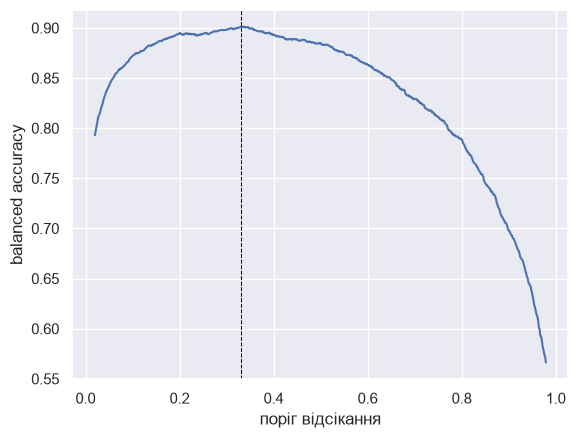

аргмаксимум за крос-валідацією: 0.331 | balanced accuracy: 0.9015


In [29]:
thresholds = np.arange(0.02, 0.98, 0.001)

scores = pd.Series(
    [balanced_accuracy_score(target, (proba_cv >= t).astype(int))
     for t in thresholds],
    index=thresholds.round(3))

threshold_cv = scores.idxmax()

ax = sns.lineplot(scores)
ax.set(xlabel='поріг відсікання', ylabel='balanced accuracy')
ax.axvline(x=threshold_cv, c='black', linestyle='--', linewidth=0.75)

plt.show()

print(f'аргмаксимум за крос-валідацією: {threshold_cv:.3f} | '
      f'balanced accuracy: {scores.max():.4f}')

Цей поріг оптимальний для моделей, навчених на 8000 рядках. Фінальна ж модель навчається на всіх 10000, і її ймовірності відкалібровані інакше - при тому самому порозі вона позначає іншу частку спостережень.

Тому переносити на фінальну модель треба не саме число, а рішення: яку частку клієнтів позначаємо як схильних до відтоку. Щоб перевірити це, а не припустити, подивимось, як обидві величини поводяться зі зростанням навчальної вибірки. Кількість фолдів задає її розмір: при `k` фолдах кожна модель бачить `10000 - 10000/k` рядків, тобто 8000, 9000 і 9500 для 5, 10 і 20 фолдів.

Рівно 10000 виміряти неможливо: щоб оцінити поріг, потрібні прогнози для спостережень, яких модель не бачила, а модель на всіх даних таких не лишає. Тому дивимось на тенденцію й переносимо ту величину, яка виявиться стабільнішою.

In [30]:
# proba_by_folds = {5: proba_cv}
#
# for n_splits in (10, 20):
#     folds = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)
#     proba_folds = np.zeros(len(X))
#
#     for train_idx, valid_idx in folds.split(X, target):
#         proba_folds[valid_idx] = fit_predict(X.iloc[train_idx],
#                                              target.iloc[train_idx],
#                                              X.iloc[valid_idx])
#
#     proba_by_folds[n_splits] = proba_folds
#     print(f'{n_splits} фолдів - готово', flush=True)
#
# fold_summary = {}
#
# for n_splits, proba_folds in proba_by_folds.items():
#     curve = pd.Series(
#         [balanced_accuracy_score(target, (proba_folds >= t).astype(int))
#          for t in thresholds],
#         index=thresholds.round(3))
#     best = curve.idxmax()
#     fold_summary[f'{n_splits} фолдів'] = {
#         'рядків на модель': len(X) - len(X) // n_splits,
#         'оптимальний поріг': best,
#         'частка позначених': (proba_folds >= best).mean(),
#         'best BA': curve.max(),
#     }
#
# pd.DataFrame(fold_summary).T.round(4)

> Код цього експерименту закоментовано: він уже дав свій висновок, а повторний запуск подовжує виконання ноутбука. Отримані значення наведено у таблиці нижче.

| Фолдів | Рядків на модель | Поріг | Частка | best BA |
|---|---|---|---|---|
| 5 | 8000 | 0.331 | 0.2252 | 0.9015 |
| 10 | 9000 | 0.318 | 0.2309 | 0.9000 |
| 20 | 9500 | 0.344 | 0.2248 | 0.8999 |

Ані поріг, ані частка не змінюються монотонно зі зростанням навчальної вибірки. Отже, систематичної залежності від обсягу даних тут не видно - це похибка оцінювання, а не тенденція.

Важливо, що ці три оцінки сильно корельовані між собою: змінюється лише кількість фолдів, а навчальні вибірки майже збігаються. Тому й розкид тут виглядає меншим, ніж він є насправді - справжню невизначеність показує наступний блок, де змінюється саме розбиття.

Виміряти оптимум для моделі, навченої на всіх 10000, неможливо: для цього не залишиться жодного відкладеного спостереження. Тому на фінальну модель переносимо не значення порогу, а операційну точку - частку позначених спостережень.

### Уточнення операційної точки

Одна крос-валідація дає лише одну випадкову реалізацію розбиття, тому й оцінка частки виходить із помітною похибкою. Повторюємо ту саму 5-кратну крос-валідацію пʼять разів із різними значеннями `random_state` і усереднюємо результат.

На відміну від попередньої таблиці, де змінювалась кількість фолдів (а навчальні вибірки при цьому майже збігались), тут кожен повтор дає інше розбиття, тож оцінки значно менш залежні одна від одної й усереднення справді зменшує розкид.

In [31]:
REPEATS = [42, 7, 2024, 13, 99]

repeat_rows = []

for seed in REPEATS:
    folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)
    proba_repeat = np.zeros(len(X))

    for train_idx, valid_idx in folds.split(X, target):
        proba_repeat[valid_idx] = fit_predict(X.iloc[train_idx],
                                              target.iloc[train_idx],
                                              X.iloc[valid_idx])

    curve = pd.Series(
        [balanced_accuracy_score(target, (proba_repeat >= t).astype(int))
         for t in thresholds],
        index=thresholds.round(3))
    best = curve.idxmax()

    repeat_rows.append({'random_state': seed,
                        'поріг': best,
                        'частка': (proba_repeat >= best).mean(),
                        'best BA': curve.max()})
    print(f'повтор {seed} - готово', flush=True)

repeats = pd.DataFrame(repeat_rows).set_index('random_state')

repeats.round(4)

повтор 42 - готово


повтор 7 - готово


повтор 2024 - готово


повтор 13 - готово


повтор 99 - готово


,поріг,частка,best BA
random_state,,,
42,0.331,0.2252,0.9015
7,0.327,0.2251,0.8967
2024,0.328,0.2202,0.8942
13,0.269,0.2439,0.8929
99,0.295,0.2345,0.8975


In [32]:
positive_rate = repeats['частка'].mean()

print(f'поріг:  середній {repeats["поріг"].mean():.3f} | '
      f'розкид {repeats["поріг"].min():.3f}-{repeats["поріг"].max():.3f} | '
      f'σ {repeats["поріг"].std():.4f}')
print(f'частка: середня {positive_rate:.4f} | '
      f'розкид {repeats["частка"].min():.4f}-{repeats["частка"].max():.4f} | '
      f'σ {repeats["частка"].std():.4f}')

print(f'\nпохибка середнього по {len(REPEATS)} повторах: '
      f'{repeats["частка"].std() / len(REPEATS) ** 0.5:.5f}')

поріг:  середній 0.310 | розкид 0.269-0.331 | σ 0.0272
частка: середня 0.2298 | розкид 0.2202-0.2439 | σ 0.0094

похибка середнього по 5 повторах: 0.00422


Розкид виявився значно більшим, ніж показував попередній блок із різною кількістю фолдів: там частка коливалась у межах 0.2248-0.2309, тут - 0.2202-0.2439, тобто вчетверо ширше. Це підтверджує, що ті три оцінки були сильно корельовані між собою, а справжню невизначеність показує саме зміна розбиття.

Порівняння двох величин: поріг має відносний розкид 8.8% (σ 0.0272 при середньому 0.310), частка - 4.1% (σ 0.0094 при середньому 0.2298). Частка оцінюється приблизно вдвічі стабільніше, тому саме її переносимо на фінальну модель.

Усереднення по пʼятьох повторах зменшує похибку оцінки з 0.0094 до 0.0042, тобто приблизно в корінь із пʼяти разів. Показово, що оцінка з одного розбиття (0.2252) відрізняється від середньої (0.2298) майже рівно на одну таку похибку - покладатись на єдине розбиття тут було б необґрунтовано.

Варто звернути увагу й на стовпець `best BA`: він коливається від 0.8929 до 0.9015 залежно від розбиття. Тобто навіть оцінка якості моделі має похибку близько 0.003, і подавати найкраще з пʼяти значень як «результат моделі» означало б обрати найвдаліший випадок. Чесніша оцінка - середнє по повторах, 0.8966.

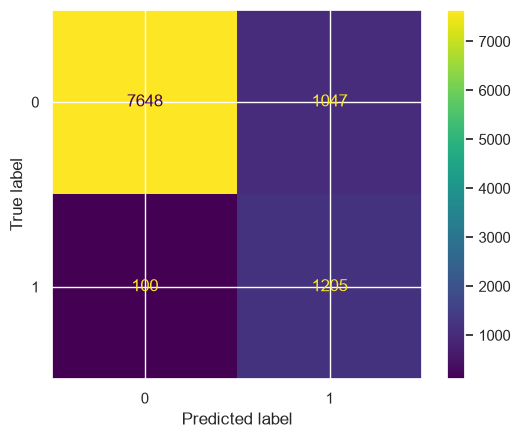

              precision    recall  f1-score   support

           0       0.99      0.88      0.93      8695
           1       0.54      0.92      0.68      1305

    accuracy                           0.89     10000
   macro avg       0.76      0.90      0.80     10000
weighted avg       0.93      0.89      0.90     10000



In [33]:
pred_cv = (proba_cv >= threshold_cv).astype(int)

ConfusionMatrixDisplay.from_predictions(target, pred_cv)
plt.show()

print(classification_report(target, pred_cv))

### Перевірка рішень щодо підготовки даних

Три рішення були прийняті раніше: залишити пропуски як є, відкинути колонки, заповнені менш ніж на 20%, і передати категорії CatBoost нативно замість кодування за цільовою змінною. Перевіряємо всі три тією ж 5-кратною крос-валідацією.

In [34]:
# def cv_variant(X_variant, impute=False, encode=False,
#                params=None, undersample=False):
#     cats = X_variant.select_dtypes(include='object').columns.tolist()
#     proba = np.zeros(len(X_variant))
#
#     for train_idx, valid_idx in cv.split(X_variant, target):
#         X_tr = X_variant.iloc[train_idx].copy()
#         X_va = X_variant.iloc[valid_idx].copy()
#         y_tr = target.iloc[train_idx]
#         cat_features = cats
#
#         if impute:
#             nums = X_tr.select_dtypes(include='number').columns
#             median = X_tr[nums].median()
#             X_tr[nums] = X_tr[nums].fillna(median)
#             X_va[nums] = X_va[nums].fillna(median)
#
#         if encode:
#             encoder = TargetEncoder(random_state=42)
#             X_tr[cats] = encoder.fit_transform(X_tr[cats], y_tr)
#             X_va[cats] = encoder.transform(X_va[cats])
#             cat_features = []
#
#         if undersample:
#             X_tr, y_tr = RandomUnderSampler(
#                 random_state=42).fit_resample(X_tr, y_tr)
#
#         model = CatBoostClassifier(**(params or PARAMS))
#         model.fit(Pool(X_tr, y_tr, cat_features=cat_features))
#         proba[valid_idx] = model.predict_proba(
#             Pool(X_va, cat_features=cat_features))[:, 1]
#
#     curve = pd.Series(
#         [balanced_accuracy_score(target, (proba >= t).astype(int))
#          for t in thresholds],
#         index=thresholds.round(3))
#
#     return {'ROC AUC': roc_auc_score(target, proba),
#             'BA @0.5': balanced_accuracy_score(
#                 target, (proba >= 0.5).astype(int)),
#             'best BA': curve.max()}

In [35]:
# base_scores = {'ROC AUC': roc_auc_score(target, proba_cv),
#                'BA @0.5': balanced_accuracy_score(
#                    target, (proba_cv >= 0.5).astype(int)),
#                'best BA': scores.max()}
#
# checks = {'пропуски як є, нативні категорії (базовий)': base_scores}
#
# checks['медіанна імпутація числових'] = cv_variant(X, impute=True)
# checks['цільове кодування замість нативного'] = cv_variant(X, encode=True)
#
# for share in (0.5, 0.95):
#     cols = [col for col in data.columns[na_share.lt(share)]
#             if col not in drop_cols]
#     checks[f'поріг пропусків {share}'] = cv_variant(prepare(data, cols))
#
# pd.DataFrame(checks).T.round(4)

> Код цього експерименту закоментовано: він уже дав свій висновок, а повторний запуск подовжує виконання ноутбука. Отримані значення наведено у таблиці нижче.

| Варіант | ROC AUC | BA @0.5 | best BA |
|---|---|---|---|
| пропуски як є, нативні категорії (базовий) | 0.9637 | 0.8850 | 0.9015 |
| медіанна імпутація числових | 0.9634 | 0.8793 | 0.8953 |
| цільове кодування замість нативного | 0.9619 | 0.8696 | 0.8943 |
| поріг пропусків 0.5 | 0.9630 | 0.8804 | 0.9001 |
| поріг пропусків 0.95 | 0.9639 | 0.8837 | 0.9002 |

Усі три рішення підтвердились.

*Пропуски.* Медіанна імпутація знижує balanced accuracy з 0.9015 до 0.8953. Це узгоджується з аналізом у розділі 2: пропущеність окремих колонок повʼязана з відтоком, і заповнення пропусків стирає цей сигнал.

*Кодування категорій.* Заміна нативної обробки на кодування за цільовою змінною дає 0.8943 - найбільша втрата серед перевірених варіантів. Це очікувано з огляду на частку одноразових категорій: для них закодоване значення фактично дорівнює мітці самого спостереження.

*Поріг відкидання розріджених колонок.* Майже не впливає: різниця між 0.5, 0.8 і 0.95 лежить у межах похибки крос-валідації.

### Перевірка способу балансування класів

Позитивний клас становить лише 13%, тож дисбаланс треба врахувати. Але спосіб може бути різним: ваги класів, ручний коефіцієнт `scale_pos_weight` або зменшення більшого класу. Порівнюємо їх, а також варіант зовсім без балансування.

Ресемплінг застосовується лише до тренувальної частини кожного фолду - інакше відкладені дані змінювали б свій розподіл і оцінка була б завищеною. У конвеєрі `sklearn` те саме дає обʼєкт `Pipeline` із пакета `imblearn`, який виконує крок балансування тільки під час навчання.

In [36]:
# no_weights = {key: value for key, value in PARAMS.items()
#               if key != 'auto_class_weights'}
#
# neg_pos = (target == 0).sum() / (target == 1).sum()
#
# balancing = {"auto_class_weights='Balanced' (базовий)": base_scores}
#
# balancing['без балансування'] = cv_variant(X, params=no_weights)
#
# balancing[f'scale_pos_weight = {neg_pos:.2f}'] = cv_variant(
#     X, params=dict(no_weights, scale_pos_weight=neg_pos))
#
# balancing['зменшення більшого класу'] = cv_variant(
#     X, params=no_weights, undersample=True)
#
# pd.DataFrame(balancing).T.round(4)

> Код цього експерименту закоментовано: він уже дав свій висновок, а повторний запуск подовжує виконання ноутбука. Отримані значення наведено у таблиці нижче.

| Варіант | ROC AUC | BA @0.5 | best BA |
|---|---|---|---|
| `auto_class_weights='Balanced'` (базовий) | 0.9637 | 0.8850 | 0.9015 |
| без балансування | 0.9627 | 0.7919 | 0.8942 |
| `scale_pos_weight = 6.66` | 0.9637 | 0.8850 | 0.9015 |
| зменшення більшого класу | 0.9539 | 0.8838 | 0.8846 |

Балансування потрібне, але його роль вужча, ніж здається.

Без нього balanced accuracy при порозі 0.5 падає з 0.8850 до 0.7919: модель майже не позначає рідкісний клас. Проте після підбору порогу різниця стискається до 0.8942 проти 0.9015. Основну частину ефекту дає не зважування, а вибір порогу - ваги зміщують ймовірності, а не змінюють порядок спостережень.

`scale_pos_weight = 6.66` збігається з `auto_class_weights='Balanced'` до четвертого знака за всіма метриками, і не випадково: `Balanced` обчислює саме відношення кількості класів. Це два записи одного прийому.

Зменшення більшого класу програє помітно: щоб зрівняти класи, довелося б відкинути близько 7400 рядків разом із інформацією.

### Підбір гіперпараметрів

Параметри CatBoost досі бралися як задані. Перевіряємо їх ручним перебором: по черзі змінюємо глибину дерева, темп навчання та силу регуляризації, залишаючи решту без змін, і оцінюємо тією ж крос-валідацією за balanced accuracy.

In [37]:
# overrides = [dict(depth=4), dict(depth=8),
#              dict(learning_rate=0.02), dict(learning_rate=0.05),
#              dict(l2_leaf_reg=3), dict(l2_leaf_reg=30)]
#
# tuning = {'базовий: depth=6, learning_rate=0.03, l2_leaf_reg=10': base_scores}
#
# for override in overrides:
#     label = ', '.join(f'{key}={value}' for key, value in override.items())
#     tuning[label] = cv_variant(X, params=dict(PARAMS, **override))
#
# pd.DataFrame(tuning).T.sort_values('best BA', ascending=False).round(4)

> Код цього експерименту закоментовано: він уже дав свій висновок, а повторний запуск подовжує виконання ноутбука. Отримані значення наведено у таблиці нижче.

| Конфігурація | ROC AUC | BA @0.5 | best BA |
|---|---|---|---|
| базова: depth=6, learning_rate=0.03, l2_leaf_reg=10 | 0.9637 | 0.8850 | 0.9015 |
| l2_leaf_reg=3 | 0.9626 | 0.8718 | 0.9007 |
| learning_rate=0.05 | 0.9625 | 0.8709 | 0.8988 |
| learning_rate=0.02 | 0.9634 | 0.8910 | 0.8985 |
| l2_leaf_reg=30 | 0.9636 | 0.8877 | 0.8983 |
| depth=8 | 0.9628 | 0.8589 | 0.8982 |
| depth=4 | 0.9630 | 0.8915 | 0.8972 |

Жоден із перевірених варіантів не покращив результат. Базова конфігурація дає найкращу balanced accuracy, а весь розкид - 0.8972-0.9015, тобто менше половини відсоткового пункта на сім конфігурацій.

Показово, що balanced accuracy при порозі 0.5 змінюється значно сильніше - від 0.8589 до 0.8915. Гіперпараметри помітно впливають на калібрування ймовірностей, але майже не змінюють порядок спостережень, від якого залежить метрика в оптимальній точці.

### Ансамбль різних алгоритмів

Окремі моделі з розділу 4 помиляються на різних спостереженнях, тому їх прогнози можна поєднати. Ймовірності різних алгоритмів мають різний масштаб, тож усереднюємо не самі значення, а ранги - так жодна модель не домінує лише через впевненіші ймовірності. Використовуємо ті самі out-of-fold прогнози, тому додаткового навчання не потрібно.

In [38]:
# from scipy.stats import rankdata
#
# oof_proba['CatBoost'] = proba_cv
#
# members = ['RandomForest', 'HistGradientBoosting', 'CatBoost']
#
# ensemble = np.mean([rankdata(oof_proba[name]) / len(X) for name in members],
#                    axis=0)
#
# ensemble_curve = pd.Series(
#     [balanced_accuracy_score(target, (ensemble >= t).astype(int))
#      for t in thresholds],
#     index=thresholds.round(3))
#
# comparison = pd.DataFrame({
#     'ансамбль трьох моделей': {'ROC AUC': roc_auc_score(target, ensemble),
#                                'best BA': ensemble_curve.max()},
#     'CatBoost окремо': {'ROC AUC': roc_auc_score(target, proba_cv),
#                         'best BA': scores.max()},
# }).T
#
# comparison.round(4)

> Код цього експерименту закоментовано: він уже дав свій висновок, а повторний запуск подовжує виконання ноутбука. Отримані значення наведено у таблиці нижче.

| Варіант | ROC AUC | best BA |
|---|---|---|
| ансамбль трьох моделей | 0.9623 | 0.8942 |
| CatBoost окремо | 0.9637 | 0.9015 |

Ансамбль програє одиночному CatBoost. Причина - у різній силі учасників: RandomForest дає 0.8742, HistGradientBoosting - 0.8875, CatBoost - 0.9015. Рівне усереднення рангів підтягує слабші моделі й тягне найсильнішу вниз. Ансамбль виграє тоді, коли моделі приблизно рівні за якістю й помиляються на різних спостереженнях.

### Важливість ознак

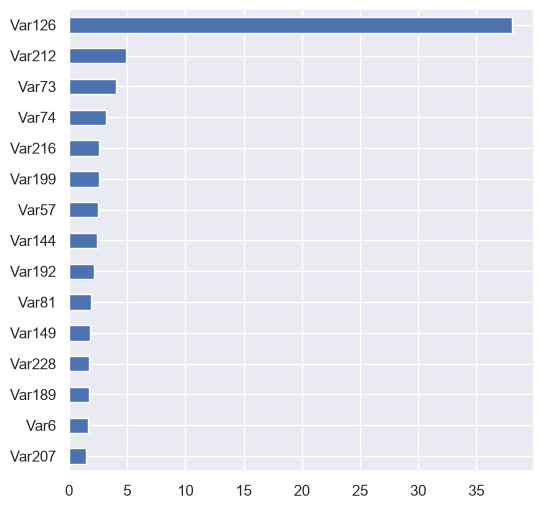

In [39]:
model_full = CatBoostClassifier(**PARAMS)
model_full.fit(Pool(X, target, cat_features=cat_cols))

(pd.Series(model_full.get_feature_importance(), index=X.columns)
 .sort_values(ascending=False)
 .head(15)
 .sort_values()
 .plot
 .barh(figsize=(6, 6)))

plt.show()

### Незалежна перевірка на відкладеній вибірці

Усі оцінки вище отримані крос-валідацією, причому поріг підбирався на тих самих out-of-fold прогнозах, за якими рахується метрика. Через це значення трохи завищене.

Щоб отримати неупереджену оцінку, ділимо розмічені дані на тренувальну й тестову частини. Поріг підбираємо лише всередині тренувальної частини, а тестову використовуємо один раз - для вимірювання. Вона не бере участі ні в навчанні, ні в підборі порогу.

In [40]:
# X_train, X_holdout, y_train, y_holdout = train_test_split(
#     X, target, test_size=0.2, stratify=target, random_state=42)
#
# inner_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
#
# proba_train = np.zeros(len(X_train))
#
# for train_idx, valid_idx in inner_cv.split(X_train, y_train):
#     proba_train[valid_idx] = fit_predict(X_train.iloc[train_idx],
#                                          y_train.iloc[train_idx],
#                                          X_train.iloc[valid_idx])
#
# curve_train = pd.Series(
#     [balanced_accuracy_score(y_train, (proba_train >= t).astype(int))
#      for t in thresholds],
#     index=thresholds.round(3))
#
# threshold_holdout = curve_train.idxmax()
#
# model_train = CatBoostClassifier(**PARAMS)
# model_train.fit(Pool(X_train, y_train, cat_features=cat_cols))
#
# proba_holdout = model_train.predict_proba(
#     Pool(X_holdout, cat_features=cat_cols))[:, 1]
#
# holdout_score = balanced_accuracy_score(
#     y_holdout, (proba_holdout >= threshold_holdout).astype(int))
#
# print(f'тренувальна частина: {len(X_train)} | тестова: {len(X_holdout)}')
# print(f'поріг за тренувальною частиною: {threshold_holdout:.3f}')
# print(f'balanced accuracy на тестовій частині: {holdout_score:.4f}')
# print(f'для порівняння, оцінка за крос-валідацією: {scores.max():.4f}')

> Код цього експерименту закоментовано: він уже дав свій висновок, а повторний запуск подовжує виконання ноутбука. Отримані значення наведено у таблиці нижче.

| | Значення |
|---|---|
| тренувальна частина | 8000 |
| тестова частина | 2000 |
| поріг за тренувальною частиною | 0.246 |
| **balanced accuracy на тестовій частині** | **0.9046** |
| для порівняння, за крос-валідацією | 0.9015 |

Незалежна перевірка не виявила завищення - різниця навіть додатна.

Це не доводить, що оптимізму немає. Відкладена частина містить лише 2000 спостережень, серед них близько 260 позитивних, тому стандартна похибка balanced accuracy на ній - приблизно 0.010. Різниця в 0.003 повністю вкладається в цю похибку.

Що справді випливає: завищення від підбору порогу невелике, інакше воно перевищило б похибку. Показовий і сам поріг: на тренувальній частині оптимальним виявився 0.246, а на всіх даних - 0.331.

## 6. Прогноз для валідаційного набору

Тепер, коли модель перевірена на відкладеній частині, навчаємо її заново на всіх розмічених даних - тренувальна й тестова частини разом. Модель із розділу вище бачила 8000 рядків, фінальна бачить усі 10000.

Валідаційний набір (`final_proj_test.csv`) до навчання не входить: у ньому немає цільової змінної, тож навчатись на ньому нема на чому. Саме для нього й будується прогноз.

Оскільки фінальна модель навчена на більшій кількості даних, поріг перераховуємо: беремо частку, визначену крос-валідацією, і застосовуємо її до прогнозів фінальної моделі. Значення порогу при цьому зміниться, а рішення - яку частку клієнтів позначати - лишиться тим самим.

In [41]:
print(f'фінальна модель навчена на {len(X)} рядках')
print(f'моделі крос-валідації бачили по {len(X) - len(X) // 5} рядків')

proba_test = model_full.predict_proba(
    Pool(X_test, cat_features=cat_cols))[:, 1]

n_positive = int(round(positive_rate * len(X_test)))
threshold_final = np.sort(proba_test)[::-1][n_positive - 1]

print(f'\nчастка з крос-валідації: {positive_rate:.4f}')
print(f'поріг для фінальної моделі: {threshold_final:.3f} '
      f'(за крос-валідацією був {threshold_cv:.3f})')

pred_test = (proba_test >= threshold_final).astype(int)

pd.Series(pred_test).value_counts(normalize=True)

фінальна модель навчена на 10000 рядках
моделі крос-валідації бачили по 8000 рядків

частка з крос-валідації: 0.2298
поріг для фінальної моделі: 0.278 (за крос-валідацією був 0.331)


0    0.7704
1    0.2296
Name: proportion, dtype: float64

In [42]:
submission = pd.DataFrame({'index': test.index,
                           'y': pred_test})

submission.to_csv('submission.csv', index=False)

submission.head()

,index,y
0,0,0
1,1,0
2,2,0
3,3,0
4,4,0


Прогнози оцінюються автоматично, тому формат файлу має збігатися з очікуваним точно. Звіряємось із шаблоном `final_proj_sample_submission.csv`, який іде разом із даними змагання: однакова кількість рядків, ті самі назви колонок і ті самі ідентифікатори в тому ж порядку.

In [43]:
sample = pd.read_csv(data_path('final_proj_sample_submission.csv'))

checks = {
    'кількість рядків': len(submission) == len(sample),
    'назви колонок': list(submission.columns) == list(sample.columns),
    'ідентифікатори збігаються': submission['index'].equals(sample['index']),
    'лише значення 0 та 1': set(submission['y'].unique()) <= {0, 1},
    'немає пропусків': bool(submission.notna().all().all()),
}

for name, passed in checks.items():
    print(f'{name}: {"так" if passed else "НІ"}')

print(f'\nпозитивних: {submission["y"].sum()} із {len(submission)} '
      f'({submission["y"].mean():.1%})')

кількість рядків: так
назви колонок: так
ідентифікатори збігаються: так
лише значення 0 та 1: так
немає пропусків: так

позитивних: 574 із 2500 (23.0%)


In [44]:
with open('submission.csv') as file:
    print(''.join(file.readlines()[:6]), end='')

index,y
0,0
1,0
2,0
3,0
4,0


## 7. Висновки

**Результат.** CatBoost показав ROC AUC 0.9637. Balanced accuracy при стандартному порозі 0.5 становить 0.8850, а після підбору порогу - **0.8966 ± 0.0033**. Це середнє по пʼятьох повторах крос-валідації з різними розбиттями; на окремому розбитті значення коливається від 0.8929 до 0.9015, тому наводити одне з них як результат моделі означало б обрати найвдаліше.

Незалежна перевірка на відкладеній вибірці, яка не використовувалась ні для навчання, ні для підбору порогу, дала **0.9046**.

**Хід роботи**

1. *Пропуски.* З 231 колонки 18 не містять жодного значення, а 154 заповнені менш ніж на 20%. Відновлювати такі колонки немає на чому, тому залишено 76 колонок із часткою пропусків меншою за 0.8. Числові пропуски CatBoost обробляє нативно, окремої імпутації для основної моделі не потрібно.
2. *Дублювання ознак.* `Var200` і `Var214` мають по 4478 категорій і рівно 4478 унікальних пар значень - це одна ознака у двох позначеннях. До того ж 78% їхніх заповнених значень у валідаційному наборі є категоріями, відсутніми в навчальних даних (для порівняння: `Var217` - 39.6%, `Var202` - 15.1%). Пару вилучено, у моделі залишилось 75 ознак, з них 32 категоріальні. `Var217` і `Var202` збережено: їх вилучення знижувало метрику.
3. *Категоріальні ознаки.* Кардинальність сягає 5529 категорій на 10 000 спостережень, тому one-hot кодування непридатне. CatBoost обробляє категорії нативно через впорядковані цільові статистики. Це не AutoML: ознаки, модель і параметри задано явно.
4. *Дисбаланс класів.* Частка позитивного класу - 13%. Використано `auto_class_weights='Balanced'`. Самих ваг недостатньо: при стандартному порозі 0.5 balanced accuracy становить 0.8850, тому поріг розглянуто окремо (пункт 5).
5. *Поріг відсікання.* Аргмаксимум кривої за крос-валідацією - 0.331 (balanced accuracy 0.9015). Фінальна модель навчається на 10000 рядках замість 8000, і калібрування її ймовірностей інше: при тому самому порозі вона позначає 21.5% рядків замість 22.5%. Тому на неї переноситься не значення порогу, а операційна точка - частка позначених спостережень. Пʼять повторів крос-валідації з різними розбиттями показали, що частка оцінюється приблизно вдвічі стабільніше за поріг: відносний розкид 4.1% проти 8.8%. Тому переносимо саме її, беручи середнє по повторах (0.2298) замість оцінки з одного розбиття. Для фінальної моделі це дає поріг 0.278.
6. *Порівняння моделей.* У ML-конвеєрі з однаковою попередньою обробкою: LogisticRegression - 0.8009, RandomForest - 0.8742, HistGradientBoosting - 0.8875. CatBoost із нативними категоріями випереджає їх усі.
7. *Зменшення розмірності.* PCA (95% дисперсії числових ознак) погіршив HistGradientBoosting із 0.8875 до 0.8405: PCA застосовний лише до числової частини, а основний сигнал несуть категоріальні ознаки, і лінійні комбінації ускладнюють деревам пошук порогів розбиття.
8. *Фінальний прогноз.* Модель навчено на всіх 10 000 розмічених спостереженнях, поріг перераховано за усередненою часткою з крос-валідації і дорівнює 0.278. У валідаційному наборі позитивними позначено 574 із 2500 рядків (23.0%), файл `submission.csv` сформовано у форматі `index,y` і звірено з шаблоном змагання.

**Методологічні зауваження**

- Попередню обробку базових моделей винесено всередину `Pipeline`, тому відновлення пропусків, масштабування та кодування категорій виконуються окремо на кожному фолді й не спричиняють витоку.
- Оцінка порогу нестабільна: аргмаксимум кривої помітно залежить від розбиття - 0.269-0.331 на пʼятьох повторах крос-валідації і 0.246 на окремій тренувальній частині. Сама метрика при цьому змінюється слабко, бо в околі оптимуму крива полога. Тому конкретному значенню порогу не варто надавати великої ваги; стабільнішою величиною є частка позначених спостережень.
- Поза цим ноутбуком перевірено також усереднення за кількома `random_seed`, стекінг із LightGBM та XGBoost і ручний перебір кількох конфігурацій гіперпараметрів (глибина дерева, темп навчання, параметри кодування категорій). Жоден варіант не дав стійкого виграшу, тому у фінальному рішенні залишено просту одиночну модель.
- Так само поза ноутбуком перевірено об'єднання рідкісних категорій у спільну групу - так, щоб нові категорії валідаційного набору отримували статистику цієї групи, а не апріорну ймовірність. Метрика від цього не зросла за жодного порогу рідкісності: CatBoost і без того згладжує рідкісні категорії у впорядкованих цільових статистиках, а групування лише втрачає деталізацію.
- Поріг підбирається на тих самих out-of-fold прогнозах, за якими звітується метрика, тому це оцінка згори. Незалежна перевірка на відкладеній вибірці дала 0.9046, тобто завищення не виявлено - але й спростувати його вона не може: на 2000 спостережень стандартна похибка balanced accuracy становить близько 0.010, і різниця в 0.003 у неї вкладається.
- Калібрування ймовірностей (ізотонічна регресія, Platt scaling) не підвищило б досяжної balanced accuracy: ці перетворення монотонні, тобто не змінюють порядку прогнозів, а отже і ROC-кривої. Воно лише дозволило б брати поріг із теорії - для balanced accuracy оптимум на каліброваних ймовірностях дорівнює частці позитивного класу - замість емпіричного підбору.
- AutoML не використовувався. Усі етапи - EDA, відбір ознак, порівняння моделей, крос-валідація, підбір порогу та навчання фінальної моделі - реалізовано явно.

**Що можна спробувати далі**

Простір для покращення метрики виглядає майже вичерпаним: усі перевірені варіанти (частину з них - поза цим ноутбуком) - ансамблі, усереднення за випадковим станом, перебір гіперпараметрів, різні способи кодування категорій - лишалися в межах balanced accuracy 0.896-0.901 за крос-валідацією.

Показово, що ROC AUC становить 0.9637, а balanced accuracy - лише 0.8966. Модель добре впорядковує спостереження за ризиком відтоку, але класи частково перекриваються, і жоден поріг не розділяє їх суттєво краще. Це радше межа інформативності наявних ознак, ніж брак налаштування, тому помітного зростання варто очікувати передусім від нових даних про клієнтів, а не від іншої моделі.

З технічних прийомів неперевіреним лишається явне додавання добутків і відношень числових ознак. Самі по собі взаємодії дерева відтворюють послідовними розбиттями, проте відношення двох змінних вони наближають східчасто, тому готова похідна ознака інколи допомагає.